# Loan Analytics Platform
## 01 - Data Understanding

**CRISP-DM phase:** Data Understanding

This notebook performs a read-only inspection of the raw loan dataset. It documents the dataset source, structure, data types, completeness, duplication, distributions, categorical composition, date coverage, and possible target variables.

> Scope guardrail: this notebook does not clean data, impute missing values, engineer features, build models, or produce EDA-style business conclusions. The source dataset is never modified.

## 1. Notebook objective

The goal is to build an auditable first view of the portfolio data before any preparation or modeling decisions are made. In a financial institution, this step is essential for identifying data-quality risks, understanding portfolio composition, and documenting potential outcome fields without prematurely changing the evidence.

### 1.1 Dataset source and business context

The raw dataset used in this project is stored locally as:

`data/raw/loan_dataset_investor.xlsx`

Based on the file name, schema, and loan-level fields, this dataset is treated as public investor/loan reporting data associated with **Bondora**, the European lending and investment platform behind products such as **Go & Grow**.

This type of public loan-level reporting is generally published to support transparency. It allows investors, analysts, researchers, and data-science practitioners to inspect loan characteristics, repayment behavior, loan status, and portfolio performance using anonymized historical records.

In this project, the file is used strictly as a local raw dataset for analysis. Each row is interpreted as a loan record, and the columns describe fields such as country, issue date, issued amount, interest rate, repayment behavior, loan status, default indicators, and projected return.

Useful public reference links for source verification and future documentation updates:

- Bondora official website: https://www.bondora.com/
- Bondora Go & Grow statistics page: https://goandgrow.eu/en/public-statistics

Important note: this notebook analyzes the local copy of the dataset. If the official source pages, field definitions, or download process change, the source notes and data dictionary should be updated.

## 2. Import libraries and configure the environment

The notebook uses Pandas and NumPy for inspection, Matplotlib for compact distribution grids, and Plotly Express for interactive portfolio summaries. Display options are configured so wide loan records remain reviewable.

In [13]:
from io import StringIO
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import Markdown, display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

plt.style.use('seaborn-v0_8-whitegrid')

RANDOM_STATE = 42
PREVIEW_ROWS = 5
TOP_CATEGORIES = 15
UNIQUE_VALUES_TO_DISPLAY = 20
PLOT_SAMPLE_SIZE = 50_000
PLOTS_PER_FIGURE = 9

## 3. Load the raw dataset

The path and sheet selector are defined in one configuration cell for easy reuse with another loan dataset. The loader reads the source as-is and raises a clear error for unsupported formats.

In [14]:

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'loan_dataset_investor.xlsx'
DATA_SHEET = 0
REPORTS_DIR = PROJECT_ROOT / 'reports'

print(f'Dataset path: {DATA_PATH}')
print(f'Dataset exists: {DATA_PATH.exists()}')

Dataset path: C:\Users\aitmo\financial-loan-analytics\data\raw\loan_dataset_investor.xlsx
Dataset exists: True


In [15]:
def load_dataset(path, sheet_name=0):
    """Load a tabular dataset without changing source values"""
    if not path.exists():
        raise FileNotFoundError(
            f'Dataset not found at {path}. Update DATA_PATH and rerun.'
        )

    suffix = path.suffix.lower()
    if suffix in {'.xlsx', '.xlsm', '.xls'}:
        return pd.read_excel(path, sheet_name=sheet_name)
    if suffix == '.csv':
        return pd.read_csv(path)
    if suffix in {'.tsv', '.txt'}:
        return pd.read_csv(path, sep='\t')

    raise ValueError(f'Unsupported dataset format: {suffix}')


# Loading is intentionally read-only: no values or dtypes are overwritten.
df = load_dataset(DATA_PATH, sheet_name=DATA_SHEET)
print(f'Loaded {len(df):,} rows and {df.shape[1]:,} columns.')

Loaded 737,889 rows and 31 columns.


## 4. Dataset overview

Shape and record previews provide a fast structural check. Head, tail, and random records help reveal whether the file is ordered, whether schemas drift near the end, and whether values look plausible across the portfolio.

In [16]:
overview = pd.DataFrame(
    {
        'metric': ['Rows', 'Columns'],
        'value': [df.shape[0], df.shape[1]],
    }
)
display(overview)

display(Markdown('### First rows'))
display(df.head(PREVIEW_ROWS))

display(Markdown('### Last rows'))
display(df.tail(PREVIEW_ROWS))

display(Markdown('### Random sample'))
sample_size = min(PREVIEW_ROWS, len(df))
display(df.sample(n=sample_size, random_state=RANDOM_STATE))

display(Markdown('### Column names'))
column_catalog = pd.DataFrame(
    {'position': range(1, df.shape[1] + 1), 'column': df.columns}
)
display(column_catalog)

,metric,value
0,Rows,737889
1,Columns,31


### First rows

,loan_id,country,loan_issued_at,early_repaid_at,is_early_repaid_within_14_days,issued_amount,loan_status,loan_last_recorded_action_date_local,initial_interest_rate,nr_of_payments,principal_balance,principal_debt,principal_paid_total,interest_paid_total,extra_interest_paid_total,late_fee_paid_total,maintenance_fee_paid_total,is_default,next_payment_nr,next_payment_date_local,debt_occured_date_local,days_past_due_principal,months_in_default,months_on_book,loan_status_risk,repaid_amount_total,initial_loan_duration,combined_income,has_default_within_12_months,projected_npv_return,customer_risk_rating
0,0B3B642A-F923-49AD-84ED-B2A700BF1D0A,Finland,2025-03-21 11:45:56.040,2025-04-04 10:50:01.137,1.0000,310.0000,Repaid,2025-04-04,0.1780,1,0.0000,0.0000,310.0000,1.9900,0.0000,0.0000,0.0000,0.0000,0.0000,NaT,NaT,NaN,NaN,0.0000,Cancelled,311.9900,12,"2,068.6800",0.0000,0.0189,F
1,4FD1927C-0E7F-4BF1-AED0-B268011E3E85,Finland,2025-01-17 17:27:25.447,NaT,NaN,414.0000,Active,NaT,0.1780,120,301.4900,0.0000,112.5100,70.8300,0.0000,0.0000,3.2700,0.0000,11.0000,2026-05-08,NaT,NaN,NaN,15.0000,Active,186.6100,18,"1,469.5000",0.0000,0.1242,B
2,7362E260-54DC-4798-8848-B18C00A59FCB,Finland,2024-06-11 10:04:52.427,2025-01-02 12:07:32.807,0.0000,518.0000,Repaid,2025-01-02,0.1877,8,0.0000,0.0000,518.0000,51.6000,0.0000,0.0000,0.0000,0.0000,0.0000,NaT,NaT,NaN,NaN,6.0000,Paid Up,569.6000,60,"4,513.2000",0.0000,0.1200,B
3,8C7E5FB6-A673-4148-BCCF-B27500B0368E,Finland,2025-01-30 10:52:12.657,NaT,NaN,"3,731.0000",Active,NaT,0.1780,75,"3,305.8700",0.0000,425.1300,724.9300,0.0000,0.0000,22.6300,0.0000,14.0000,2026-05-04,NaT,NaN,NaN,15.0000,Active,"1,172.6900",60,"1,301.0000",0.0000,0.1014,C
4,BE865034-6041-4855-AB42-B196014FA0E8,Netherlands,2024-06-21 20:48:23.787,NaT,NaN,"3,432.0000",Active,NaT,0.1056,38,"2,371.8200",0.0000,"1,060.1800",549.6600,0.2900,0.0000,60.6500,0.0000,1.0000,2026-05-01,NaT,NaN,NaN,22.0000,Active,"1,670.7800",60,"5,194.7000",0.0000,0.1094,A


### Last rows

,loan_id,country,loan_issued_at,early_repaid_at,is_early_repaid_within_14_days,issued_amount,loan_status,loan_last_recorded_action_date_local,initial_interest_rate,nr_of_payments,principal_balance,principal_debt,principal_paid_total,interest_paid_total,extra_interest_paid_total,late_fee_paid_total,maintenance_fee_paid_total,is_default,next_payment_nr,next_payment_date_local,debt_occured_date_local,days_past_due_principal,months_in_default,months_on_book,loan_status_risk,repaid_amount_total,initial_loan_duration,combined_income,has_default_within_12_months,projected_npv_return,customer_risk_rating
737884,9F87D65D-F33E-4A35-845F-A7EC008F3C00,Estonia,2017-09-12 09:09:16,NaT,NaN,"10,630.0000",Repaid,2022-12-30,0.3693,18,0.0000,0.0000,"9,280.0500","9,933.5800",33.9600,0.0000,"1,480.7100",0.0000,0.0000,NaT,2021-11-12,413.0000,NaN,50.0000,Written Off,"20,728.3000",60,NaN,0.0000,NaN,NaN
737885,6F032FC5-B40C-4E66-B0F1-AE1600AE82E2,Finland,2022-01-07 12:46:19,NaT,NaN,"4,150.0000",Repaid,2023-01-24,0.1490,14,0.0000,0.0000,396.9000,361.1500,0.0000,0.0000,0.0000,0.0000,0.0000,NaT,2022-09-19,127.0000,NaN,12.0000,Written Off,758.0500,60,NaN,0.0000,NaN,NaN
737886,AD747E81-F69B-4A6F-9D3E-A7C60116D3E9,Estonia,2017-08-05 16:59:20,2019-04-12 11:30:29,0.0000,"2,445.0000",Repaid,2019-04-12,0.1610,9,0.0000,0.0000,"2,445.0000",577.7800,2.3400,0.0000,164.8000,0.0000,0.0000,NaT,NaT,NaN,NaN,20.0000,Paid Up,"3,189.9200",60,NaN,0.0000,NaN,NaN
737887,74B341A4-7D11-42D0-B850-AB0D00DEEA25,Estonia,2019-11-22 13:40:32,NaT,NaN,956.0000,Repaid,2024-11-08,0.2837,60,0.0000,0.0000,956.0000,832.2300,0.0000,0.0000,189.9100,0.0000,0.0000,NaT,NaT,NaN,NaN,60.0000,Paid Up,"1,978.1400",60,NaN,0.0000,NaN,NaN
737888,991E2C16-E084-436E-BB89-A906011D4331,Estonia,2018-06-22 06:43:03,NaT,NaN,"3,400.0000",Repaid,2023-05-31,0.3424,59,0.0000,0.0000,464.0100,933.0300,1.9400,0.0000,112.0100,0.0000,0.0000,NaT,2019-05-20,"1,472.0000",NaN,13.0000,Written Off,"1,510.9900",60,NaN,0.0000,NaN,NaN


### Random sample

,loan_id,country,loan_issued_at,early_repaid_at,is_early_repaid_within_14_days,issued_amount,loan_status,loan_last_recorded_action_date_local,initial_interest_rate,nr_of_payments,principal_balance,principal_debt,principal_paid_total,interest_paid_total,extra_interest_paid_total,late_fee_paid_total,maintenance_fee_paid_total,is_default,next_payment_nr,next_payment_date_local,debt_occured_date_local,days_past_due_principal,months_in_default,months_on_book,loan_status_risk,repaid_amount_total,initial_loan_duration,combined_income,has_default_within_12_months,projected_npv_return,customer_risk_rating
418551,2BC2B05B-2E84-42F0-857D-AA8300B981E5,Spain,2019-07-07 11:20:39.000,NaT,NaN,"1,590.0000",Defaulted,NaT,0.3050,36,"1,316.0200","1,316.0200",273.9800,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,NaT,2019-08-05,"2,456.0000",78.0000,3.0000,Defaulted,273.9800,36,NaN,1.0000,NaN,NaN
671511,257D5D69-90D8-410A-999D-B193014B8410,Finland,2024-06-18 20:12:56.493,NaT,NaN,"4,249.0000",Active,NaT,0.1877,60,"3,124.3600",0.0000,"1,124.6400","1,255.1700",0.0000,0.0000,118.4600,0.0000,23.0000,2026-05-04,NaT,NaN,NaN,22.0000,Active,"2,498.2700",60,"2,107.4400",0.0000,0.1114,B
574207,7FC80EF1-C986-4DFC-B9A3-B1EC00A69E7F,Finland,2024-09-15 10:12:01.247,NaT,NaN,"1,451.0000",Active,NaT,0.1877,120,"1,302.3900",0.0000,148.6100,397.0400,0.0000,0.0000,28.1500,0.0000,5.0000,2026-05-12,NaT,NaN,NaN,19.0000,Active,573.8000,60,"1,899.4400",0.0000,0.1254,B
41447,713B3239-0D9D-4A7B-AB05-A9C801314D36,Finland,2019-01-01 18:39:50.000,NaT,NaN,"4,250.0000",Repaid,2025-10-29,0.5973,60,0.0000,0.0000,24.8600,549.4100,0.2400,0.0000,36.8500,0.0000,0.0000,NaT,2019-04-23,"2,381.0000",NaN,6.0000,Written Off,611.3600,60,NaN,1.0000,NaN,NaN
380073,A74408DE-1634-49B7-9336-B00800D5B0F0,Finland,2023-05-20 13:22:22.000,NaT,NaN,"4,146.0000",Repaid,2025-10-29,0.1927,24,0.0000,0.0000,"2,585.4100",752.4100,0.0000,0.0000,0.0000,0.0000,0.0000,NaT,2024-06-17,499.0000,NaN,16.0000,Written Off,"3,337.8200",60,"1,156.2900",0.0000,0.0631,NaN


### Column names

,position,column
0,1,loan_id
1,2,country
2,3,loan_issued_at
3,4,early_repaid_at
4,5,is_early_repaid_within_14_days
5,6,issued_amount
6,7,loan_status
7,8,loan_last_recorded_action_date_local
8,9,initial_interest_rate
9,10,nr_of_payments


## 5. Dataset information

Data types determine which statistical methods are valid, while memory usage informs the engineering approach needed for reproducible analysis at portfolio scale.

In [17]:
info_buffer = StringIO()
df.info(buf=info_buffer, show_counts=True, memory_usage='deep')
print(info_buffer.getvalue())

display(Markdown('### Data types'))
dtype_table = df.dtypes.astype(str).rename('dtype').to_frame()
display(dtype_table)

display(Markdown('### Deep memory usage by column'))
memory_usage = df.memory_usage(index=True, deep=True).sort_values(
    ascending=False
).rename('bytes').to_frame()
memory_usage['megabytes'] = memory_usage['bytes'] / (1024 ** 2)
display(memory_usage)
print(f'Total deep memory usage: {memory_usage.megabytes.sum():,.2f} MB')

<class 'pandas.DataFrame'>
RangeIndex: 737889 entries, 0 to 737888
Data columns (total 31 columns):
 #   Column                                Non-Null Count   Dtype         
---  ------                                --------------   -----         
 0   loan_id                               737889 non-null  str           
 1   country                               737889 non-null  str           
 2   loan_issued_at                        737889 non-null  datetime64[us]
 3   early_repaid_at                       212484 non-null  datetime64[us]
 4   is_early_repaid_within_14_days        212484 non-null  float64       
 5   issued_amount                         737889 non-null  float64       
 6   loan_status                           737889 non-null  str           
 7   loan_last_recorded_action_date_local  337604 non-null  datetime64[us]
 8   initial_interest_rate                 737889 non-null  float64       
 9   nr_of_payments                        737889 non-null  int64         


### Data types

,dtype
loan_id,str
country,str
loan_issued_at,datetime64[us]
early_repaid_at,datetime64[us]
is_early_repaid_within_14_days,float64
issued_amount,float64
loan_status,str
loan_last_recorded_action_date_local,datetime64[us]
initial_interest_rate,float64
nr_of_payments,int64


### Deep memory usage by column

,bytes,megabytes
loan_id,32467116,30.9631
loan_status_risk,11439616,10.9097
country,11227895,10.7078
loan_status,10636463,10.1437
customer_risk_rating,6494517,6.1937
early_repaid_at,5903112,5.6296
is_early_repaid_within_14_days,5903112,5.6296
loan_issued_at,5903112,5.6296
principal_debt,5903112,5.6296
initial_interest_rate,5903112,5.6296


Total deep memory usage: 215.29 MB


## 6. Missing values analysis

Missingness can affect risk estimates, monitoring coverage, and regulatory reporting. This section quantifies nulls without filling or otherwise changing them.

In [18]:
missing_count = df.isna().sum()
missing_percentage = missing_count.div(len(df)).mul(100)

missing_table = pd.DataFrame(
    {
        'missing_count': missing_count,
        'missing_percentage': missing_percentage,
    }
).sort_values(
    ['missing_percentage', 'missing_count'],
    ascending=False,
)
display(missing_table)

missing_only = missing_table.loc[
    missing_table['missing_count'].gt(0)
].reset_index(names='column')

if missing_only.empty:
    print('No missing values were identified.')
else:
    figure = px.bar(
        missing_only.sort_values('missing_percentage'),
        x='missing_percentage',
        y='column',
        orientation='h',
        text='missing_count',
        title='Missing Values by Column',
        labels={
            'missing_percentage': 'Missing values (%)',
            'column': 'Column',
        },
        color='missing_percentage',
        color_continuous_scale='Blues',
    )
    figure.update_layout(
        height=max(450, 28 * len(missing_only)),
        coloraxis_showscale=False,
    )
    figure.update_traces(texttemplate='%{text:,}', textposition='outside')
    figure.show()

,missing_count,missing_percentage
months_in_default,637048,86.3339
early_repaid_at,525405,71.2038
is_early_repaid_within_14_days,525405,71.2038
debt_occured_date_local,525129,71.1664
days_past_due_principal,525129,71.1664
next_payment_date_local,428662,58.0930
loan_last_recorded_action_date_local,400285,54.2473
customer_risk_rating,339601,46.0233
combined_income,273156,37.0186
projected_npv_return,272284,36.9004


## 7. Duplicate analysis

Exact duplicate rows can overstate portfolio exposure and bias aggregate statistics. They are counted here but intentionally retained for later business-rule validation.

In [19]:
duplicate_count = int(df.duplicated().sum())
duplicate_percentage = (
    duplicate_count / len(df) * 100 if len(df) else 0.0
)

duplicate_summary = pd.DataFrame(
    {
        'metric': ['Duplicate rows', 'Duplicate percentage'],
        'value': [duplicate_count, duplicate_percentage],
    }
)
display(duplicate_summary)
print(f'Duplicate rows: {duplicate_count:,} ({duplicate_percentage:.4f}%)')

,metric,value
0,Duplicate rows,0.0000
1,Duplicate percentage,0.0000


Duplicate rows: 0 (0.0000%)


## 8. Numerical features analysis

Numerical distributions reveal scale differences, heavy tails, possible outliers, and low-variance fields relevant to later risk analytics. All statistics use the full dataset. Plotting alone uses a reproducible sample when the dataset is large, which keeps the notebook responsive without changing the underlying calculations.

In [20]:
numerical_columns = df.select_dtypes(include=[np.number]).columns.tolist()
column_unique_counts = df.nunique(dropna=True)

print(f'Numerical features identified: {len(numerical_columns)}')
display(pd.DataFrame({'numerical_column': numerical_columns}))

if numerical_columns:
    numerical_summary = df[numerical_columns].describe().T
    numerical_summary['skewness'] = df[numerical_columns].skew()
    numerical_summary['kurtosis'] = df[numerical_columns].kurtosis()
    numerical_summary['unique_values'] = column_unique_counts[
        numerical_columns
    ]
    display(numerical_summary)
else:
    numerical_summary = pd.DataFrame()
    print('No numerical features were identified.')

Numerical features identified: 21


,numerical_column
0,is_early_repaid_within_14_days
1,issued_amount
2,initial_interest_rate
3,nr_of_payments
4,principal_balance
5,principal_debt
6,principal_paid_total
7,interest_paid_total
8,extra_interest_paid_total
9,late_fee_paid_total


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,unique_values
is_early_repaid_within_14_days,"212,484.0000",0.1521,0.3591,0.0000,0.0000,0.0000,0.0000,1.0000,1.9376,1.7544,2
issued_amount,"737,889.0000","2,233.2080","2,314.9345",6.3900,530.0000,"1,400.0000","3,627.0000","20,000.0000",1.9971,5.7534,8612
initial_interest_rate,"737,889.0000",0.2175,0.1376,0.0100,0.1748,0.1877,0.2269,2.6431,6.3847,71.5199,6285
nr_of_payments,"737,889.0000",51.5534,44.4312,1.0000,8.0000,43.0000,91.0000,180.0000,0.4300,-1.2929,142
principal_balance,"730,176.0000",996.0697,"1,864.2254",-34.2000,0.0000,132.5500,"1,178.0000","20,000.0000",3.3461,15.4947,191329
principal_debt,"730,176.0000",271.7525,964.5922,0.0000,0.0000,0.0000,0.0000,"17,886.9200",5.1594,34.9674,84043
principal_paid_total,"730,176.0000","1,090.1834","1,611.6832",0.0000,99.2800,474.1000,"1,382.0000","20,000.0000",2.7868,11.1418,162392
interest_paid_total,"730,176.0000",484.4312,907.9004,0.0000,33.6700,158.2000,557.8425,"31,998.7100",5.8209,66.7391,175146
extra_interest_paid_total,"730,176.0000",1.1468,27.5583,0.0000,0.0000,0.0000,0.0000,"5,755.7700",80.8357,"10,249.9106",6508
late_fee_paid_total,"730,176.0000",0.4401,20.4108,0.0000,0.0000,0.0000,0.0000,"5,154.1600",111.5198,"18,595.7895",3202


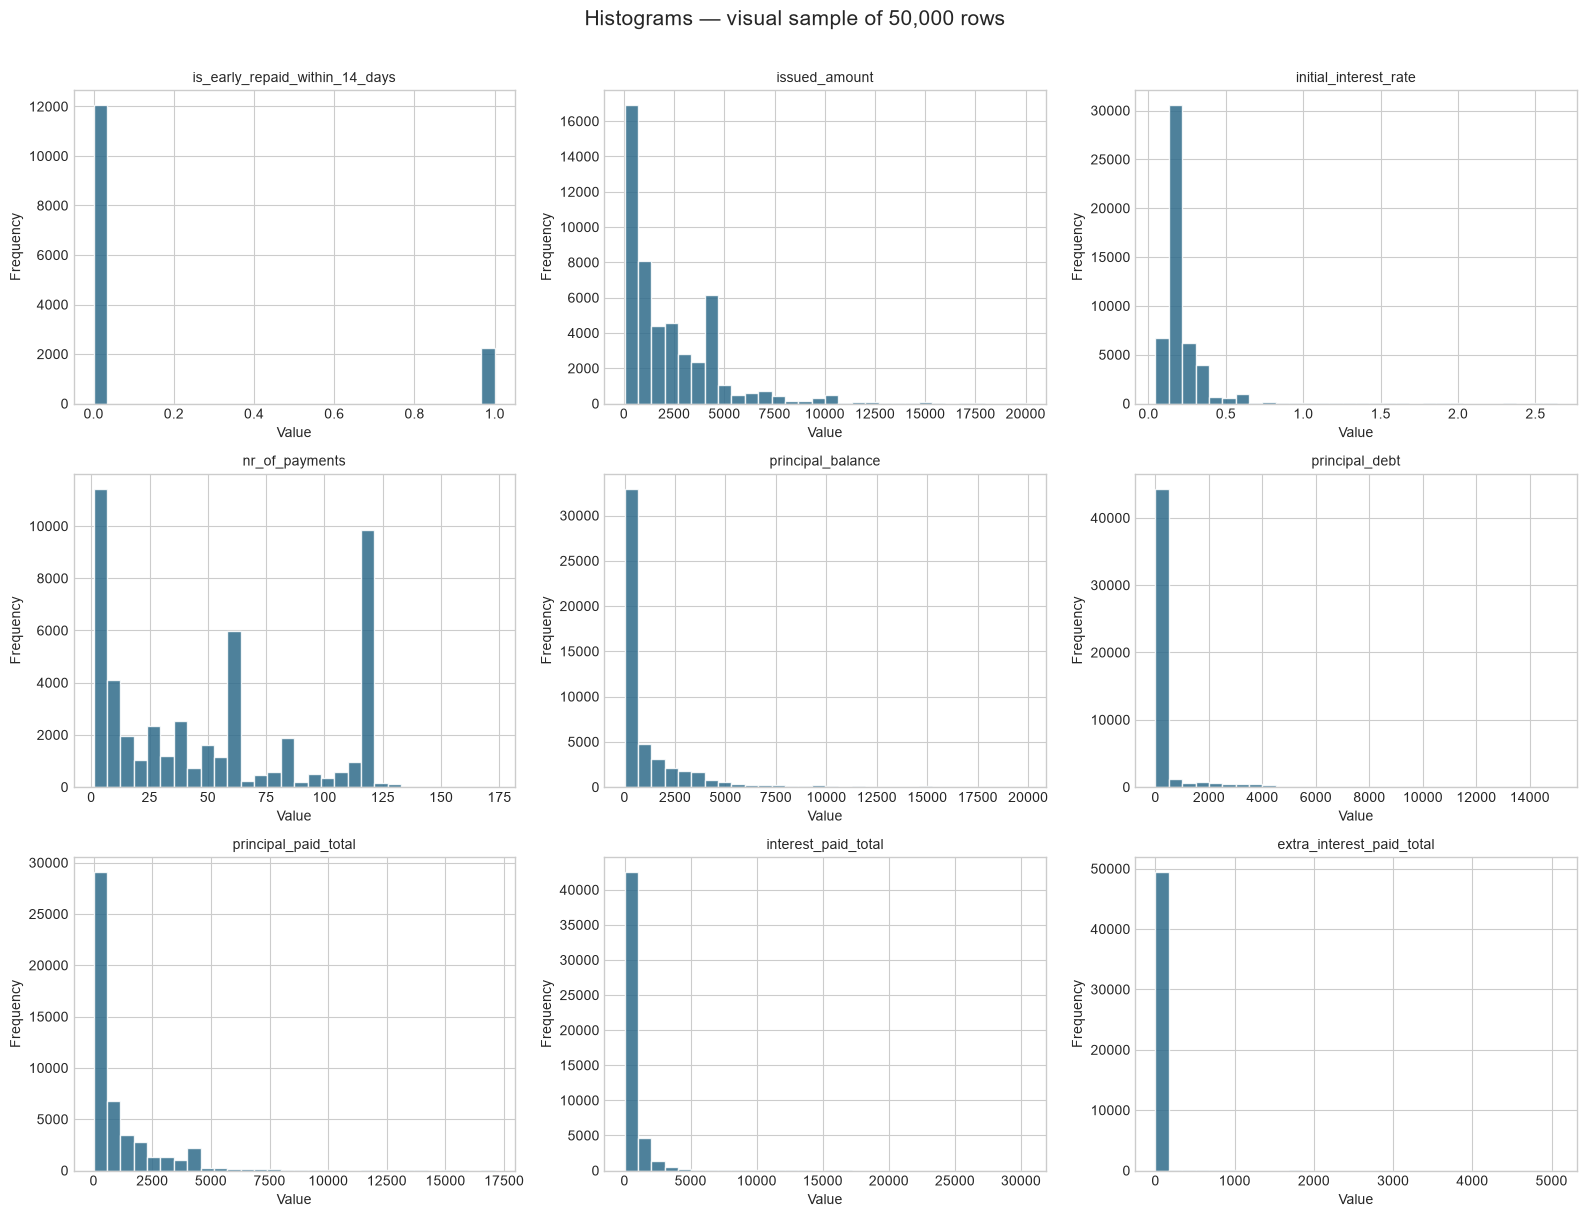

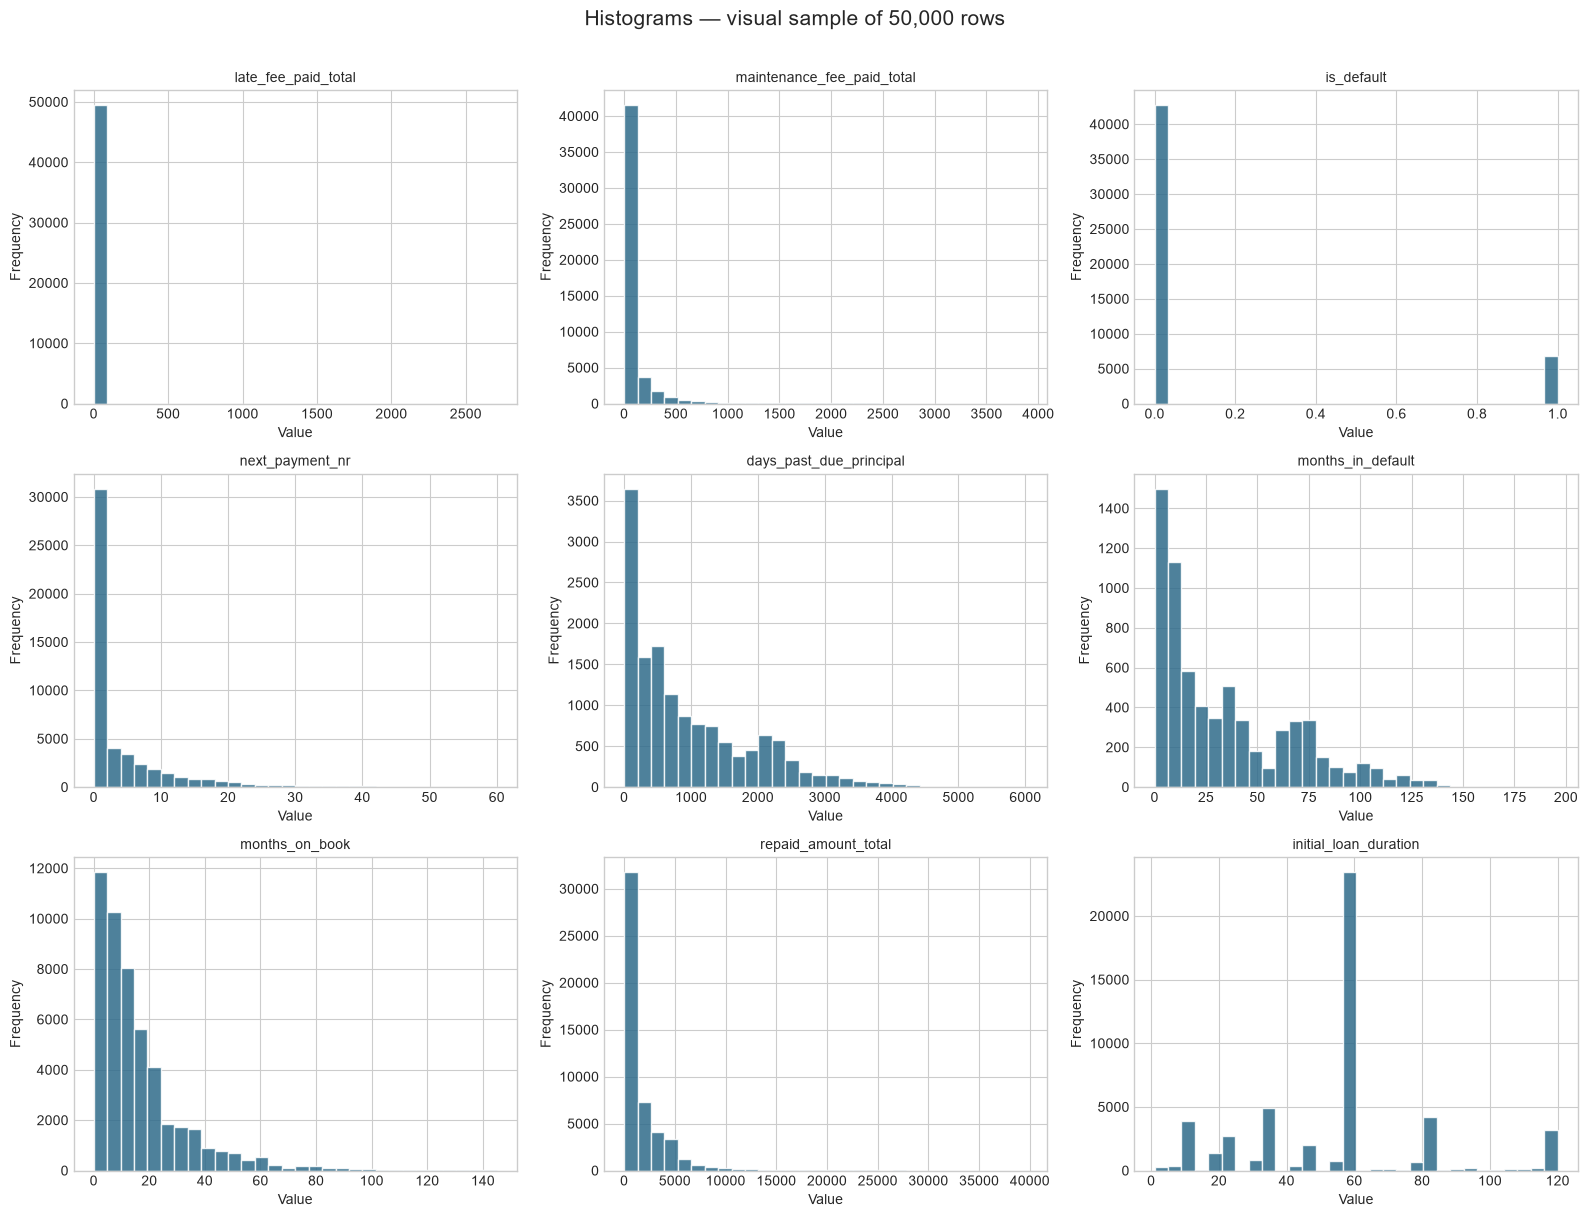

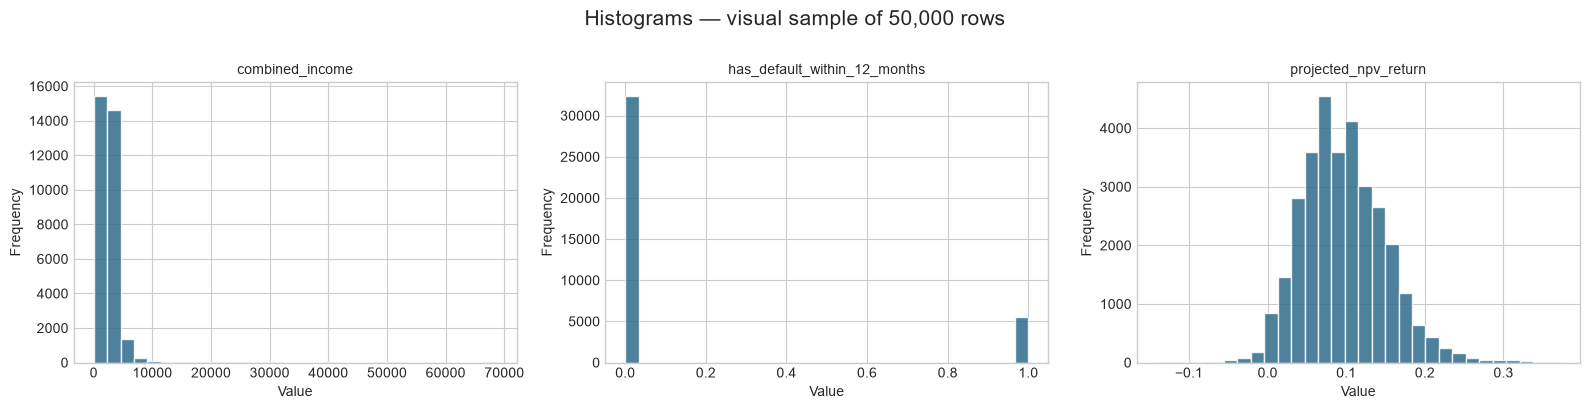

In [21]:
def _plot_numeric_grid(
    dataframe,
    columns,
    plot_type,
    sample_size=PLOT_SAMPLE_SIZE,
):
    """Plot every numerical feature in readable, sampled chart grids."""
    if not columns:
        print('No numerical columns are available to plot.')
        return

    rows_to_plot = min(sample_size, len(dataframe))
    plot_data = dataframe[columns].sample(
        n=rows_to_plot,
        random_state=RANDOM_STATE,
    )

    for start in range(0, len(columns), PLOTS_PER_FIGURE):
        batch = columns[start:start + PLOTS_PER_FIGURE]
        subplot_columns = 3
        subplot_rows = ceil(len(batch) / subplot_columns)
        figure, axes = plt.subplots(
            subplot_rows,
            subplot_columns,
            figsize=(16, 4 * subplot_rows),
        )
        axes = np.atleast_1d(axes).ravel()

        for axis, column in zip(axes, batch):
            values = plot_data[column].dropna()
            if values.empty:
                axis.text(0.5, 0.5, 'No non-null values', ha='center')
            elif plot_type == 'histogram':
                axis.hist(
                    values,
                    bins=30,
                    color='#2F6B8A',
                    edgecolor='white',
                    alpha=0.85,
                )
                axis.set_ylabel('Frequency')
            elif plot_type == 'boxplot':
                axis.boxplot(
                    values,
                    orientation='horizontal',
                    patch_artist=True,
                    boxprops={'facecolor': '#86BBD8'},
                    medianprops={'color': '#B23A48', 'linewidth': 2},
                    flierprops={
                        'marker': '.',
                        'markersize': 2,
                        'alpha': 0.25,
                    },
                )
                axis.set_yticks([])
            else:
                raise ValueError(f'Unsupported plot type: {plot_type}')

            axis.set_title(str(column), fontsize=10)
            axis.set_xlabel('Value')

        for axis in axes[len(batch):]:
            axis.set_visible(False)

        title = f'{plot_type.title()}s — visual sample of {rows_to_plot:,} rows'
        figure.suptitle(title, fontsize=15, y=1.01)
        figure.tight_layout()
        plt.show()


_plot_numeric_grid(df, numerical_columns, plot_type='histogram')

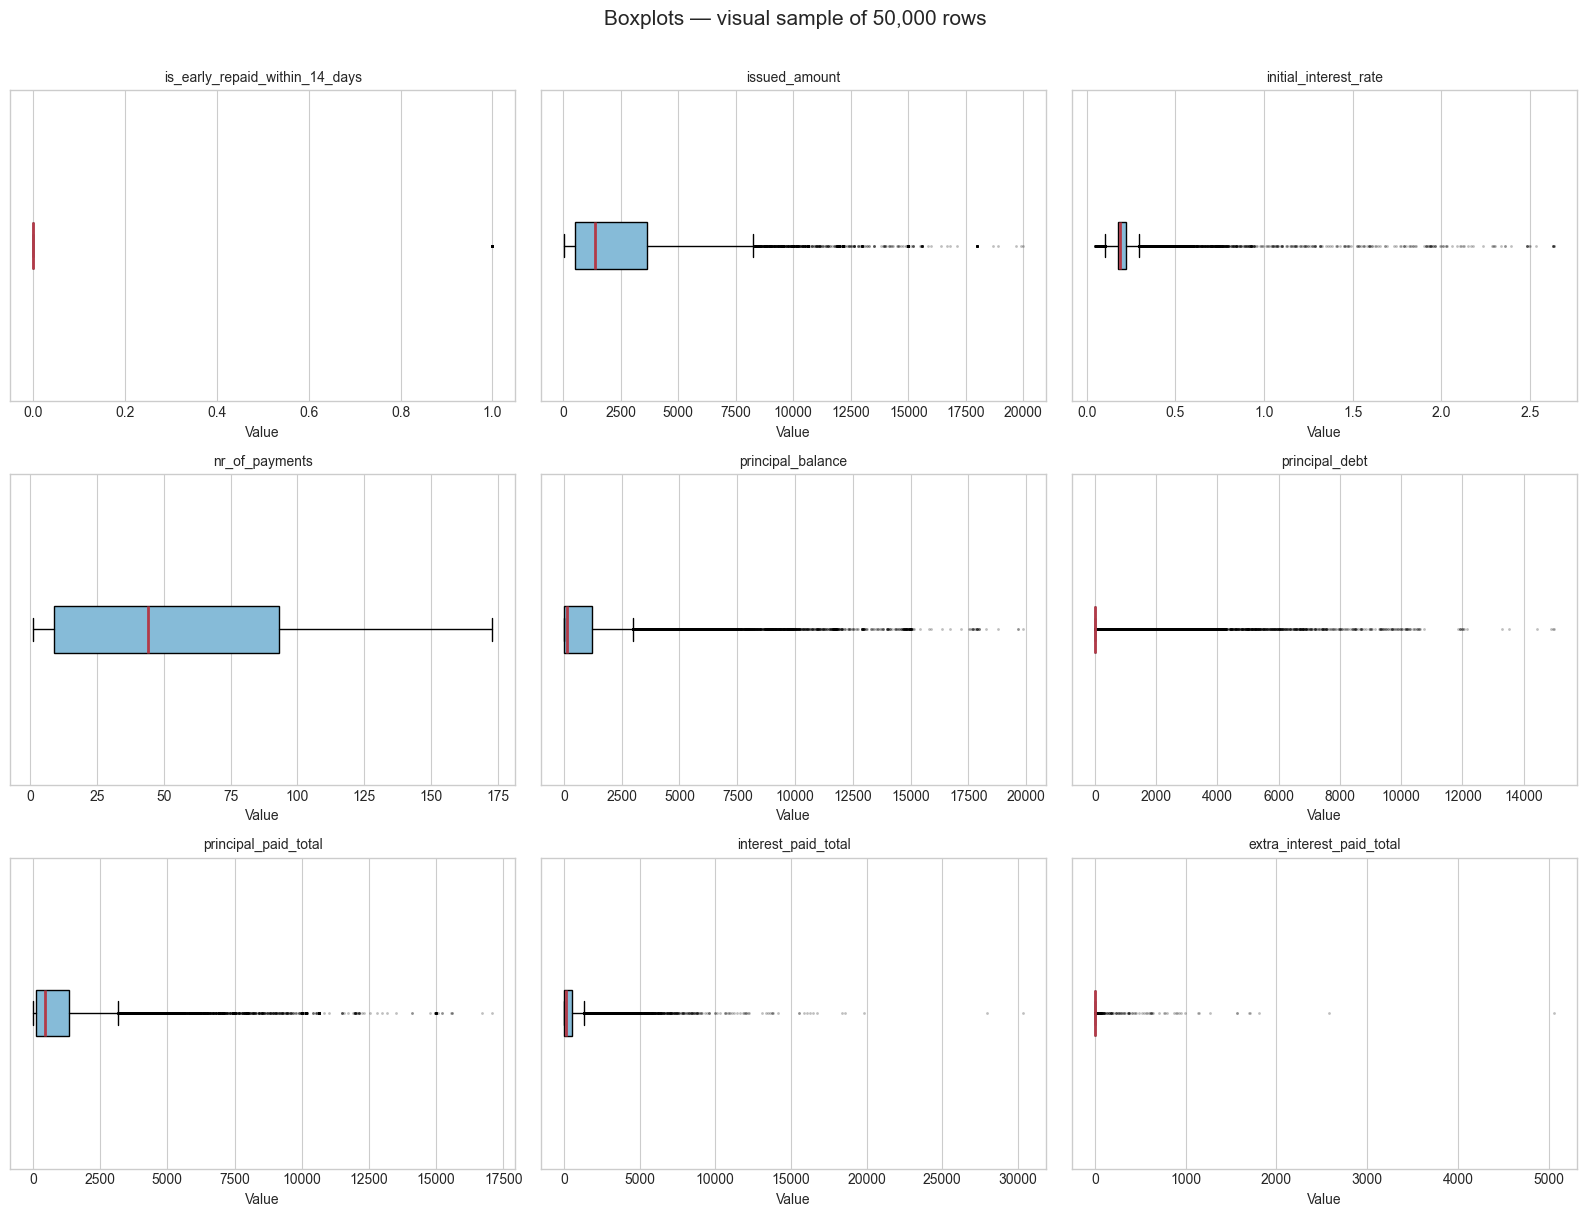

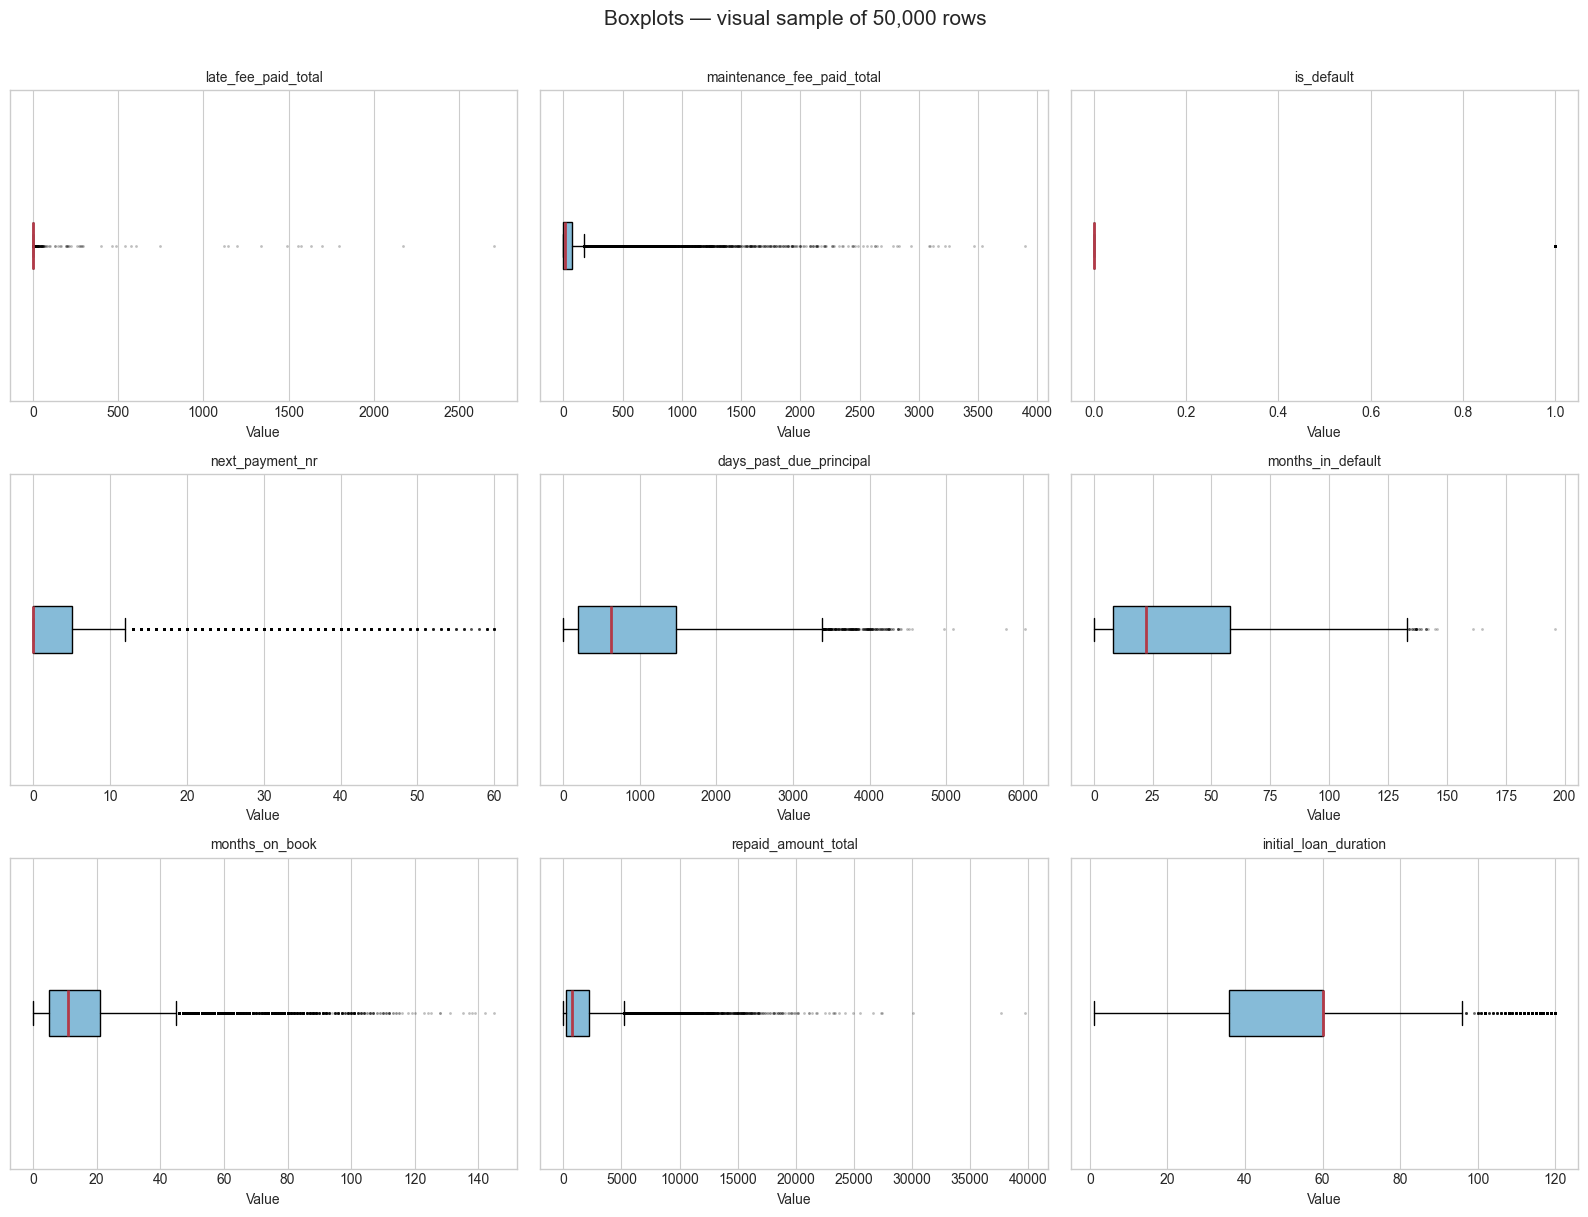

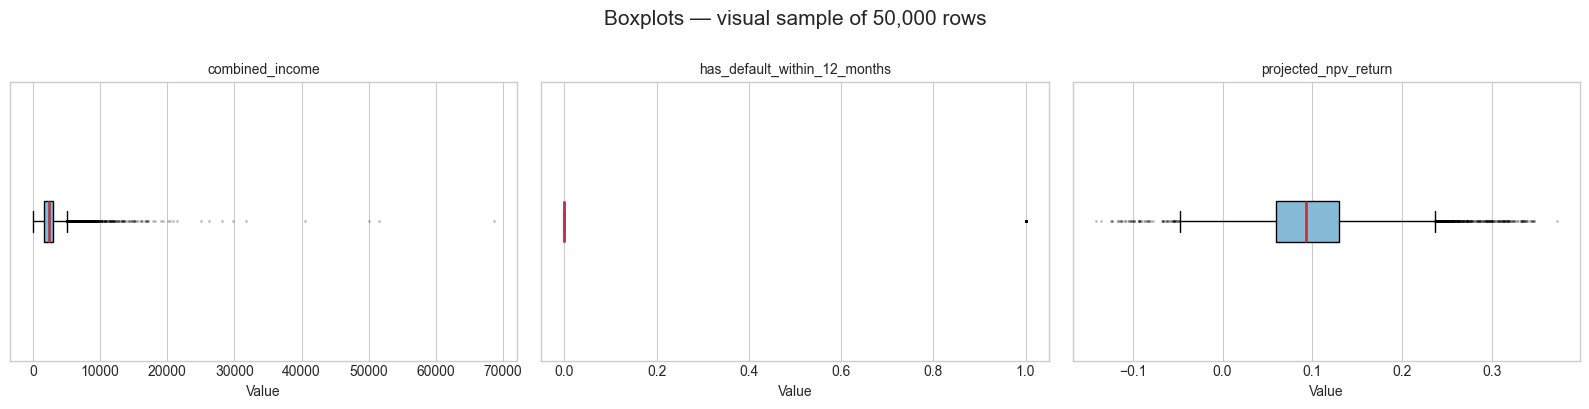

In [10]:
_plot_numeric_grid(df, numerical_columns, plot_type='boxplot')

## 9. Categorical features analysis

Categorical composition supports segmentation and concentration analysis. For each feature, the notebook reports cardinality, a bounded preview of distinct values, and the most frequent categories with counts and portfolio percentages. High-cardinality tables are deliberately truncated for readability; no categories are recoded.

In [22]:
categorical_columns = df.select_dtypes(
    exclude=[np.number, 'datetime', 'datetimetz']
).columns.tolist()

print(f'Categorical features identified: {len(categorical_columns)}')
display(pd.DataFrame({'categorical_column': categorical_columns}))

Categorical features identified: 5


,categorical_column
0,loan_id
1,country
2,loan_status
3,loan_status_risk
4,customer_risk_rating


In [23]:
def categorical_frequency_table(series):
    """Return category counts and percentages, preserving missingness."""
    labeled = series.astype('object').where(series.notna(), '<Missing>')
    counts = labeled.value_counts(dropna=False)
    percentages = counts.div(len(series)).mul(100)
    return pd.DataFrame(
        {'count': counts, 'percentage': percentages}
    ).rename_axis('category')


for column in categorical_columns:
    display(Markdown(f'### `{column}`'))

    unique_count = int(df[column].nunique(dropna=False))
    print(f'Unique values, including missing: {unique_count:,}')

    unique_preview = df[column].drop_duplicates().head(
        UNIQUE_VALUES_TO_DISPLAY
    ).rename('unique_value').to_frame()
    display(unique_preview)
    if unique_count > UNIQUE_VALUES_TO_DISPLAY:
        print(
            f'Unique-value preview truncated to '
            f'{UNIQUE_VALUES_TO_DISPLAY:,} entries.'
        )

    frequency_table = categorical_frequency_table(df[column])
    top_frequency = frequency_table.head(TOP_CATEGORIES).reset_index()
    display(top_frequency)
    if len(frequency_table) > TOP_CATEGORIES:
        print(
            f'Frequency table truncated to the {TOP_CATEGORIES} '
            'most common categories.'
        )

    chart_data = top_frequency.sort_values('count')
    figure = px.bar(
        chart_data,
        x='count',
        y='category',
        orientation='h',
        text='percentage',
        title=f'Most Common Categories — {column}',
        labels={'count': 'Records', 'category': str(column)},
        color='count',
        color_continuous_scale='Teal',
    )
    figure.update_traces(
        texttemplate='%{text:.2f}%',
        textposition='outside',
    )
    figure.update_layout(
        height=max(400, 32 * len(chart_data)),
        coloraxis_showscale=False,
    )
    figure.show()

### `loan_id`

Unique values, including missing: 737,889


,unique_value
0,0B3B642A-F923-49AD-84ED-B2A700BF1D0A
1,4FD1927C-0E7F-4BF1-AED0-B268011E3E85
2,7362E260-54DC-4798-8848-B18C00A59FCB
3,8C7E5FB6-A673-4148-BCCF-B27500B0368E
4,BE865034-6041-4855-AB42-B196014FA0E8
5,D1F62E00-BCCC-4FDF-B43B-A5E600EF3798
6,C4B05966-CB57-4F94-85E1-B1BF00AF6DEA
7,E032DA70-5633-4CEB-9230-A4FB00B8BE41
8,7094F915-4187-47B5-8F95-B40200C58A1B
9,A5320936-0A6E-41A3-8381-B28600C000BC


Unique-value preview truncated to 20 entries.


,category,count,percentage
0,0B3B642A-F923-49AD-84ED-B2A700BF1D0A,1,0.0001
1,4FD1927C-0E7F-4BF1-AED0-B268011E3E85,1,0.0001
2,7362E260-54DC-4798-8848-B18C00A59FCB,1,0.0001
3,8C7E5FB6-A673-4148-BCCF-B27500B0368E,1,0.0001
4,BE865034-6041-4855-AB42-B196014FA0E8,1,0.0001
5,D1F62E00-BCCC-4FDF-B43B-A5E600EF3798,1,0.0001
6,C4B05966-CB57-4F94-85E1-B1BF00AF6DEA,1,0.0001
7,E032DA70-5633-4CEB-9230-A4FB00B8BE41,1,0.0001
8,7094F915-4187-47B5-8F95-B40200C58A1B,1,0.0001
9,A5320936-0A6E-41A3-8381-B28600C000BC,1,0.0001


...

,category,count,percentage
0,Active,301541,40.8654
1,Paid Up,224749,30.4584
2,Defaulted,100572,13.6297
3,Written Off,78707,10.6665
4,Cancelled,32317,4.3797
5,<Missing>,3,0.0004


### `customer_risk_rating`

Unique values, including missing: 10


,unique_value
0,F
1,B
3,C
4,A
5,NaN
9,AA
11,D
12,G
90,E
10233,HR


,category,count,percentage
0,<Missing>,339601,46.0233
1,AA,100834,13.6652
2,B,83299,11.2888
3,C,68090,9.2277
4,A,67095,9.0928
5,D,39194,5.3116
6,E,22976,3.1137
7,F,9792,1.3270
8,G,6962,0.9435
9,HR,46,0.0062


## 10. Date features

Date coverage is central to vintage analysis, delinquency timelines, and prediction-horizon design. Datetime dtypes are detected directly; date-like text fields are conservatively identified from column-name cues and parse success, using temporary series only.

In [24]:
def detect_datetime_columns(
    dataframe,
    parse_threshold=0.80,
    sample_size=2_000,
):
    """Detect typed and likely text-based datetime columns read-only."""
    detected = {}
    date_name_tokens = (
        'date',
        'time',
        'issued',
        'repaid',
        'occurred',
        'occured',
        'created',
        'updated',
    )

    for column in dataframe.columns:
        series = dataframe[column]
        if pd.api.types.is_datetime64_any_dtype(series):
            detected[column] = 'datetime dtype'
            continue

        is_text_like = (
            pd.api.types.is_object_dtype(series)
            or isinstance(series.dtype, pd.StringDtype)
        )
        name_suggests_date = any(
            token in str(column).lower() for token in date_name_tokens
        )
        if not (is_text_like and name_suggests_date):
            continue

        non_null = series.dropna().head(sample_size)
        if non_null.empty:
            continue

        parsed_sample = pd.to_datetime(non_null, errors='coerce')
        if parsed_sample.notna().mean() >= parse_threshold:
            detected[column] = 'date-like text'

    return detected


date_detection = detect_datetime_columns(df)
date_columns = list(date_detection)

if not date_columns:
    date_summary = pd.DataFrame()
    print('No datetime or reliably date-like columns were identified.')
else:
    date_records = []
    for column, detection_method in date_detection.items():
        source_series = df[column]
        if pd.api.types.is_datetime64_any_dtype(source_series):
            date_series = source_series
        else:
            date_series = pd.to_datetime(source_series, errors='coerce')

        date_records.append(
            {
                'column': column,
                'detection_method': detection_method,
                'minimum_date': date_series.min(),
                'maximum_date': date_series.max(),
                'missing_dates': int(source_series.isna().sum()),
                'missing_percentage': source_series.isna().mean() * 100,
            }
        )

    date_summary = pd.DataFrame(date_records).set_index('column')
    display(date_summary)

,detection_method,minimum_date,maximum_date,missing_dates,missing_percentage
column,,,,,
loan_issued_at,datetime dtype,2009-02-28 18:05:13,2026-03-31 02:40:04.640,0,0.0000
early_repaid_at,datetime dtype,2009-05-21 08:52:43,2026-04-26 21:25:31.437,525405,71.2038
loan_last_recorded_action_date_local,datetime dtype,2009-04-14 00:00:00,2026-04-26 00:00:00.000,400285,54.2473
next_payment_date_local,datetime dtype,2009-04-15 00:00:00,2027-01-13 00:00:00.000,428662,58.0930
debt_occured_date_local,datetime dtype,2009-04-15 00:00:00,2026-04-24 00:00:00.000,525129,71.1664


## 11. Target variable discovery

A potential outcome field is discovered using a case-insensitive priority list of common loan-risk targets. This is only a hypothesis for later business validation: target suitability, observation windows, label maturity, and leakage are not resolved in this notebook.

In [25]:
TARGET_CANDIDATES = [
    'has_default_within_12_months',
    'loan_default',
    'default',
    'is_default',
    'target',
    'loan_status',
    'repayment_status',
    'status',
]

normalized_columns = {
    str(column).strip().lower(): column for column in df.columns
}
potential_target_columns = [
    normalized_columns[candidate.lower()]
    for candidate in TARGET_CANDIDATES
    if candidate.lower() in normalized_columns
]
target_column = (
    potential_target_columns[0] if potential_target_columns else None
)

if target_column is None:
    target_counts = pd.Series(dtype='int64')
    print('No obvious target variable has been identified.')
else:
    print(f'Potential target columns: {potential_target_columns}')
    print(f'Primary target candidate selected for inspection: {target_column}')

    target_labeled = df[target_column].astype('object').where(
        df[target_column].notna(),
        '<Missing>',
    )
    target_counts = target_labeled.value_counts(dropna=False)
    target_distribution = pd.DataFrame(
        {
            'count': target_counts,
            'percentage': target_counts.div(len(df)).mul(100),
        }
    ).rename_axis('class')
    display(target_distribution)

    chart_data = target_distribution.reset_index().sort_values('count')
    figure = px.bar(
        chart_data,
        x='count',
        y='class',
        orientation='h',
        text='percentage',
        title=f'Class Balance — {target_column}',
        labels={'count': 'Records', 'class': 'Target class'},
        color='count',
        color_continuous_scale='RdBu',
    )
    figure.update_traces(
        texttemplate='%{text:.2f}%',
        textposition='outside',
    )
    figure.update_layout(coloraxis_showscale=False, height=450)
    figure.show()

Potential target columns: ['has_default_within_12_months', 'is_default', 'loan_status']
Primary target candidate selected for inspection: has_default_within_12_months


,count,percentage
class,,
0.0000,480438,65.1098
<Missing>,174379,23.6321
1.0000,83072,11.2581


## 12. Initial data-quality observations

This section gives a factual summary of what was observed during data understanding. It intentionally avoids deeper EDA conclusions, causal interpretations, feature-engineering decisions, or modeling recommendations.

In [26]:
def build_data_quality_observations(dataframe):
    """Create a factual Markdown summary for the data-understanding phase."""
    row_count, column_count = dataframe.shape

    local_missing_count = dataframe.isna().sum()
    local_missing_percentage = local_missing_count.div(len(dataframe)).mul(100)
    local_missing_columns = int(local_missing_count.gt(0).sum())
    local_missing_cells = int(local_missing_count.sum())
    local_missing_cell_percentage = (
        local_missing_cells / dataframe.size * 100 if dataframe.size else 0.0
    )

    local_duplicate_count = int(dataframe.duplicated().sum())
    local_duplicate_percentage = (
        local_duplicate_count / len(dataframe) * 100 if len(dataframe) else 0.0
    )

    local_numerical_columns = dataframe.select_dtypes(
        include=[np.number]
    ).columns.tolist()
    local_categorical_columns = dataframe.select_dtypes(
        exclude=[np.number, 'datetime', 'datetimetz']
    ).columns.tolist()
    local_date_detection = detect_datetime_columns(dataframe)
    local_date_columns = list(local_date_detection)

    local_target_candidates = [
        'has_default_within_12_months',
        'loan_default',
        'default',
        'is_default',
        'target',
        'loan_status',
        'repayment_status',
        'status',
    ]
    normalized = {
        str(column).strip().lower(): column for column in dataframe.columns
    }
    local_potential_targets = [
        normalized[candidate]
        for candidate in local_target_candidates
        if candidate in normalized
    ]

    lines = [
        '### Dataset structure',
        '',
        f'- The dataset contains **{row_count:,} rows** and **{column_count:,} columns**.',
        f'- Automatic type detection found **{len(local_numerical_columns)} numerical**, '
        f'**{len(local_categorical_columns)} categorical**, and '
        f'**{len(local_date_columns)} date-like** columns.',
        '',
        '### Completeness and duplication',
        '',
        f'- **{local_missing_columns:,} columns** contain missing values.',
        f'- Missing cells represent **{local_missing_cell_percentage:.2f}%** of all dataset cells.',
        f'- Exact duplicate rows: **{local_duplicate_count:,}** '
        f'(**{local_duplicate_percentage:.4f}%**).',
    ]

    high_missing = local_missing_percentage[
        local_missing_percentage.ge(20)
    ].sort_values(ascending=False)
    if not high_missing.empty:
        examples = ', '.join(
            f'`{column}` ({value:.1f}%)'
            for column, value in high_missing.head(5).items()
        )
        lines.extend([
            '',
            '### Columns requiring later review',
            '',
            f'- High missingness was observed in: {examples}.',
            '- These fields should be reviewed later before cleaning or modeling, because missing values may have business meaning.',
        ])

    lines.extend([
        '',
        '### Candidate target fields',
        '',
    ])
    if local_potential_targets:
        targets = ', '.join(f'`{column}`' for column in local_potential_targets)
        lines.append(f'- Potential target/status fields found: {targets}.')
    else:
        lines.append('- No obvious target/status field was identified.')

    lines.extend([
        '',
        '### Scope reminder',
        '',
        '- No cleaning, imputation, feature engineering, leakage decisions, or model-building actions are performed in this notebook.',
    ])

    return chr(10).join(lines)


observations_markdown = build_data_quality_observations(df)
display(Markdown(observations_markdown))

### Dataset structure

- The dataset contains **737,889 rows** and **31 columns**.
- Automatic type detection found **21 numerical**, **5 categorical**, and **5 date-like** columns.

### Completeness and duplication

- **23 columns** contain missing values.
- Missing cells represent **20.60%** of all dataset cells.
- Exact duplicate rows: **0** (**0.0000%**).

### Columns requiring later review

- High missingness was observed in: `months_in_default` (86.3%), `is_early_repaid_within_14_days` (71.2%), `early_repaid_at` (71.2%), `days_past_due_principal` (71.2%), `debt_occured_date_local` (71.2%).
- These fields should be reviewed later before cleaning or modeling, because missing values may have business meaning.

### Candidate target fields

- Potential target/status fields found: `has_default_within_12_months`, `is_default`, `loan_status`.

### Scope reminder

- No cleaning, imputation, feature engineering, leakage decisions, or model-building actions are performed in this notebook.

## 13. Save the data dictionary

The generated dictionary provides a compact, versionable schema record for analysts, engineers, model validators, and governance stakeholders. It records observed metadata only and does not modify the raw dataset.

In [27]:
dictionary_missing_count = df.isna().sum()
dictionary_missing_percentage = dictionary_missing_count.div(len(df)).mul(100)
dictionary_unique_counts = df.nunique(dropna=True)

data_dictionary = pd.DataFrame(
    {
        'column_name': df.columns,
        'dtype': df.dtypes.astype(str).to_numpy(),
        'missing_values': dictionary_missing_count.reindex(df.columns).to_numpy(),
        'missing_percentage': dictionary_missing_percentage.reindex(
            df.columns
        ).round(4).to_numpy(),
        'unique_values': dictionary_unique_counts.reindex(df.columns).to_numpy(),
    }
)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
dictionary_path = REPORTS_DIR / 'data_dictionary.csv'
data_dictionary.to_csv(dictionary_path, index=False)

display(data_dictionary)
print(f'Data dictionary saved to: {dictionary_path}')

,column_name,dtype,missing_values,missing_percentage,unique_values
0,loan_id,str,0,0.0000,737889
1,country,str,0,0.0000,8
2,loan_issued_at,datetime64[us],0,0.0000,736948
3,early_repaid_at,datetime64[us],525405,71.2038,209430
4,is_early_repaid_within_14_days,float64,525405,71.2038,2
5,issued_amount,float64,0,0.0000,8612
6,loan_status,str,0,0.0000,5
7,loan_last_recorded_action_date_local,datetime64[us],400285,54.2473,5191
8,initial_interest_rate,float64,0,0.0000,6285
9,nr_of_payments,int64,0,0.0000,142


Data dictionary saved to: C:\Users\aitmo\financial-loan-analytics\reports\data_dictionary.csv


## Conclusion

This notebook completes the data-understanding phase by documenting the raw dataset structure, field types, missingness, duplicates, distributions, categorical values, date-like fields, candidate target/status columns, and a data dictionary.

The next notebooks should handle deeper EDA, data preparation, feature engineering, and modeling separately.